<a href="https://colab.research.google.com/github/nurfnick/Numerical_Methods/blob/master/Module_6_Regression/RegressionAdVibeCode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prompt



---

I want to generate some non-linear data. Maybe time spent studying and grade earned. Then I want to fit a linear regression to it. I want to then examine what went wrong in the regression using residuals and leverage.

### 1. Generate Non-Linear Data (Study Hours vs. Grade)
We will simulate data where grades increase with study hours but eventually level off (diminishing returns), which represents a non-linear logarithmic or quadratic-like relationship.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.graphics.regressionplots import influence_plot

# Set random seed for reproducibility
np.random.seed(42)

# Generate study hours (from 1 to 20 hours)
study_hours = np.random.uniform(1, 20, 100)

# Non-linear relationship (Logarithmic with some noise)
# Grade = 40 + 15 * ln(study_hours) + noise
noise = np.random.normal(0, 4, 100)
grades = 40 + 18 * np.log(study_hours) + noise

# Cap grades at 100
grades = np.clip(grades, 0, 100)

# Create a DataFrame
df = pd.DataFrame({'Study_Hours': study_hours, 'Grade': grades})
display(df.head())

,Study_Hours,Grade
0,8.116262,78.037844
1,19.063572,91.863998
2,14.907885,89.001068
3,12.374511,77.331223
4,3.964354,63.913486


### 2. Fit a Simple Linear Regression Model

In [2]:
# Add a constant to the independent variable (Study_Hours) for the intercept
X = sm.add_constant(df['Study_Hours'])
y = df['Grade']

# Fit the OLS model
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Grade   R-squared:                       0.856
Model:                            OLS   Adj. R-squared:                  0.855
Method:                 Least Squares   F-statistic:                     583.8
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           4.56e-43
Time:                        15:39:24   Log-Likelihood:                -302.51
No. Observations:                 100   AIC:                             609.0
Df Residuals:                      98   BIC:                             614.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          55.8013      1.022     54.613      

### 3. Analyze what went wrong using Residuals and Leverage
We will plot the fitted line against the data, analyze the residuals (errors) to see if they follow a pattern, and look at leverage to identify influential points.

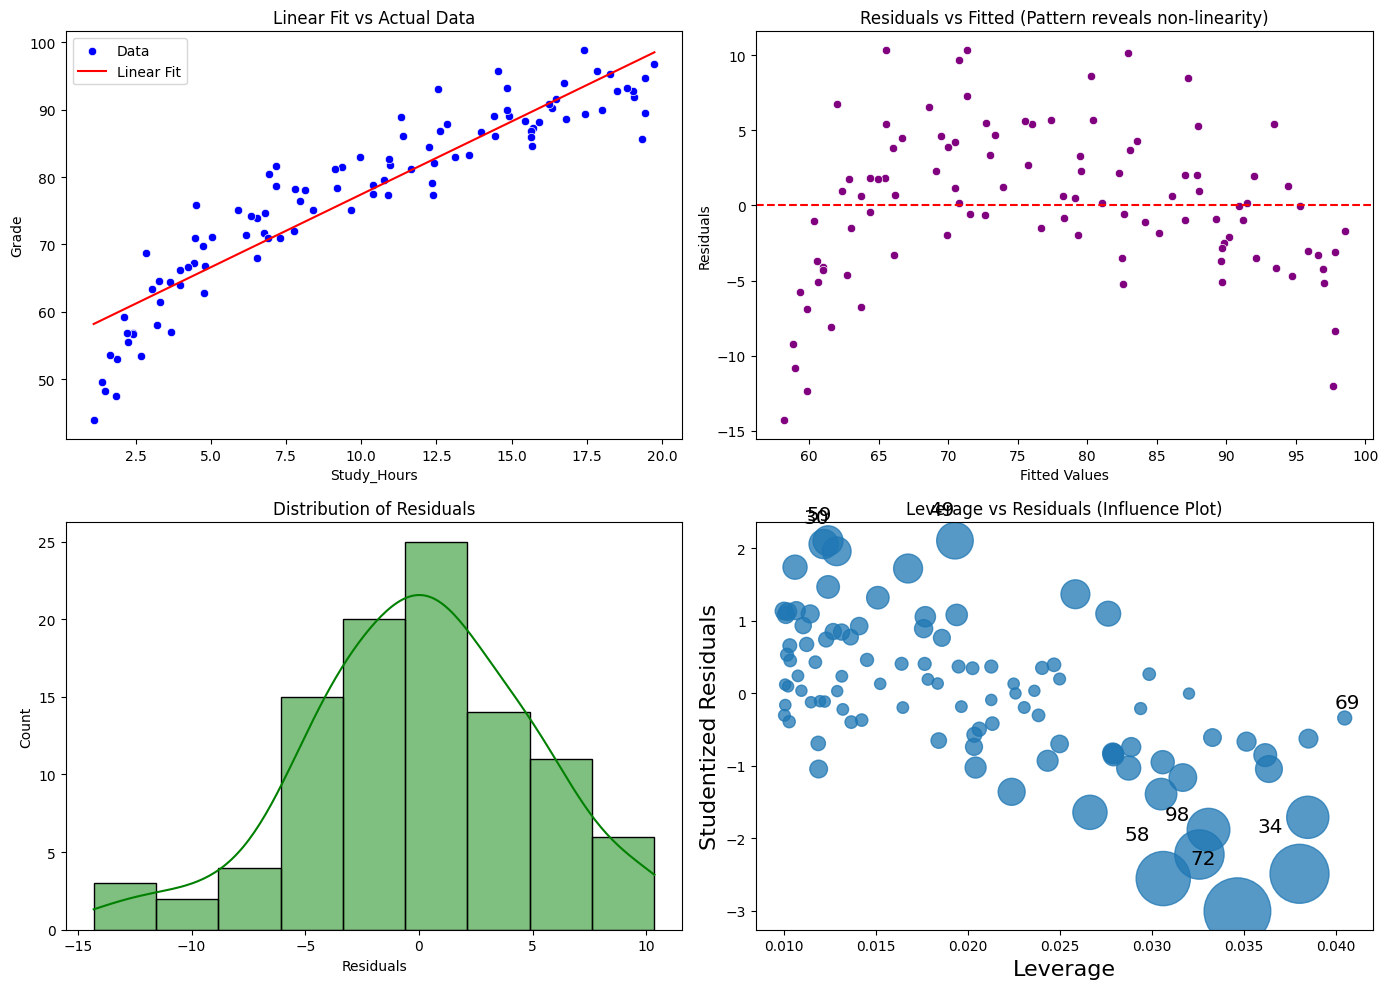

In [3]:
# Get fitted values and residuals
df['Fitted'] = model.predict(X)
df['Residuals'] = model.resid

# Calculate influence diagnostics including leverage (hat values)
influence = model.get_influence()
df['Leverage'] = influence.hat_matrix_diag

# Create Diagnostic Plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Regression Fit Plot
sns.scatterplot(data=df, x='Study_Hours', y='Grade', ax=axes[0, 0], color='blue', label='Data')
sns.lineplot(data=df, x='Study_Hours', y='Fitted', ax=axes[0, 0], color='red', label='Linear Fit')
axes[0, 0].set_title('Linear Fit vs Actual Data')
axes[0, 0].set_ylabel('Grade')

# 2. Residuals vs Fitted Plot (Should be random; a pattern indicates non-linearity)
sns.scatterplot(data=df, x='Fitted', y='Residuals', ax=axes[0, 1], color='purple')
axes[0, 1].axhline(y=0, color='red', linestyle='--')
axes[0, 1].set_title('Residuals vs Fitted (Pattern reveals non-linearity)')
axes[0, 1].set_xlabel('Fitted Values')
axes[0, 1].set_ylabel('Residuals')

# 3. Distribution of Residuals
sns.histplot(df['Residuals'], kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title('Distribution of Residuals')

# 4. Leverage vs Residuals (Influence Plot)
influence_plot(model, ax=axes[1, 1], criterion='cooks')
axes[1, 1].set_title('Leverage vs Residuals (Influence Plot)')

plt.tight_layout()
plt.show()